First 5 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Unique Species:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']

Null Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicated Values:
0

Dataset Description:
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433

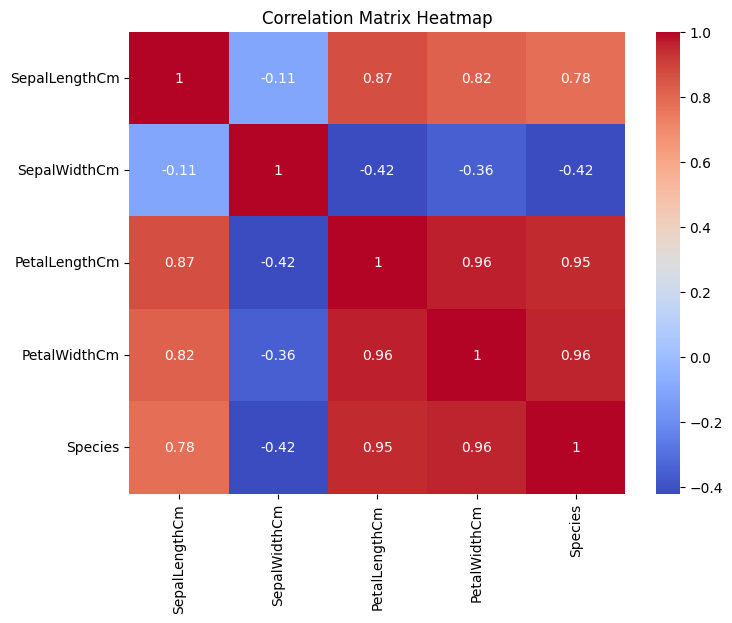


LDA Transformed Data:
          0         1
0  8.084953 -0.328454
1  7.147163  0.755473
2  7.511378  0.238078
3  6.837676  0.642885
4  8.157814 -0.540639

Training and Testing Shapes:
X Train: (120, 2)
Y Train: (120,)
X Test: (30, 2)
Y Test: (30,)

Logistic Regression Model Trained Successfully

Predictions:
[1 1 1 0 1 1 0 1 1 1 2 0 0 1 1 0 1 2 2 2 2 2 2 2 0 0 2 0 0 0]

Accuracy: 0.9667

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


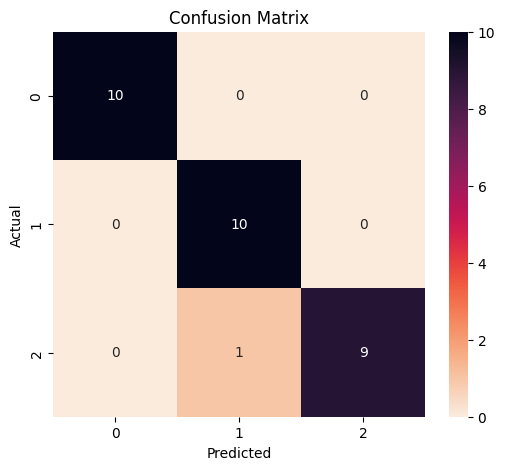


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.91      1.00      0.95        10
           2       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



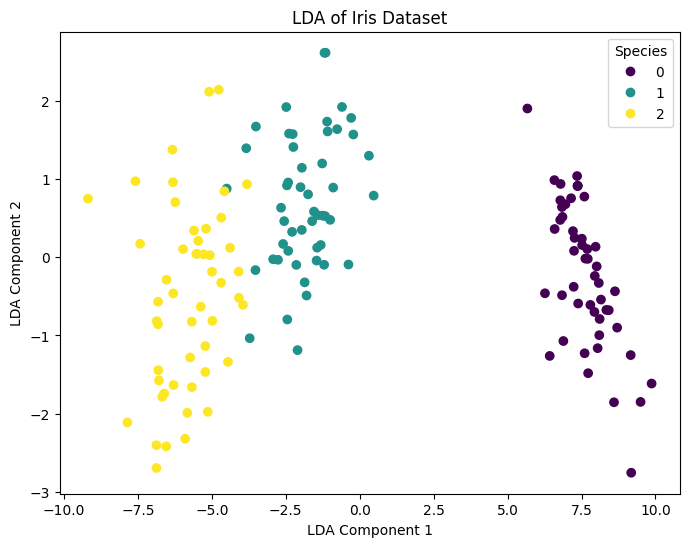

In [1]:

# Practical 3: Linear Discriminant Analysis (LDA)

# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.linear_model import LogisticRegression


# 2. Load the Dataset
raw_df = pd.read_csv(
    'Iris.csv'
)


# 3. Explore Species
print("First 5 rows:")
print(raw_df.head())

print("\nUnique Species:")
print(raw_df.Species.unique())


# 4. Check for Null Values
print("\nNull Values:")
print(raw_df.isnull().sum())


# 5. Check for Duplicated Values
print("\nDuplicated Values:")
print(raw_df.duplicated().sum())


# 6. Describe the Dataset
print("\nDataset Description:")
print(raw_df.describe())


# 7. Get Dataset Information
print("\nDataset Information:")
raw_df.info()


# 8. Drop the Id Column
raw_df.drop('Id', axis=1, inplace=True)

print("\nAfter dropping Id:")
print(raw_df.head())


# 9. Map Species to Numerical Values
raw_df.Species = raw_df.Species.map({
    'Iris-setosa': 0,
    'Iris-versicolor': 1,
    'Iris-virginica': 2
})

print("\nAfter mapping Species:")
print(raw_df.head())


# 10. Scale the Features
scaler = StandardScaler()

x = raw_df.drop('Species', axis=1)
y = raw_df.Species

x_scaled = pd.DataFrame(
    scaler.fit_transform(x),
    columns=x.columns,
    index=x.index
)

print("\nScaled Features:")
print(x_scaled.head())


# 11. Concatenate Scaled Features and Species
df = pd.concat([x_scaled, y], axis=1)

print("\nScaled Dataset:")
print(df.head())


# 12. Correlation Matrix Heatmap
corr_matrix = df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix Heatmap")
plt.show()


# 13. Apply LDA
lda = LDA(n_components=2)

x_lda = lda.fit_transform(x_scaled, y)

print("\nLDA Transformed Data:")
print(pd.DataFrame(x_lda).head())


# 14. Split Data into Training and Testing Sets
x_train, x_test, y_train, y_test = train_test_split(
    x_lda,
    y,
    test_size=0.2,
    random_state=82,
    stratify=y
)

print("\nTraining and Testing Shapes:")
print("X Train:", x_train.shape)
print("Y Train:", y_train.shape)
print("X Test:", x_test.shape)
print("Y Test:", y_test.shape)


# 15. Train Logistic Regression Model
model = LogisticRegression()

model.fit(x_train, y_train)

print("\nLogistic Regression Model Trained Successfully")


# 16. Make Predictions
y_pred = model.predict(x_test)

print("\nPredictions:")
print(y_pred)


# 17. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy, 4))


# 18. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='rocket_r'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


# 19. Classification Report
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)


# 20. Visualize LDA Results
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    x_lda[:, 0],
    x_lda[:, 1],
    c=y
)

plt.xlabel('LDA Component 1')
plt.ylabel('LDA Component 2')

plt.title('LDA of Iris Dataset')

legend = plt.legend(
    *scatter.legend_elements(),
    title="Species"
)

plt.show()
